# El Juego de los Números Uniformes
**Taller de Resolución de Problemas III — Universidad Austral — 2026**

Integrantes: Marull Victoria, Medina Inés

## Método de resolución

Resolvemos el problema de forma **analítica** y verificamos cada resultado con **simulación (Monte Carlo)**.

Lo hacemos en dos etapas:

1. **Etapa 1:** el Jugador 1 frente a un rival con un número uniforme (0,1), eligiendo para cada número la opción con mayor probabilidad de ganar.
2. **Etapa 2:** el juego completo, donde el Jugador 2 conoce la opción elegida por el Jugador 1 (pero no su número) y decide en consecuencia.

## Etapa 1: rival uniforme (0,1)

### Hipótesis

1. El número final del rival es **uniforme en (0,1)**: el rival no elige ninguna opción, tiene un número al azar.
2. El Jugador 1 elige, para cada número que le toca, la opción con **mayor probabilidad de ganar**.
3. Los números son independientes entre sí.
4. La probabilidad de empate es 0 (dos números uniformes casi nunca son iguales).

### Resolución

Nos toca un número $x$ y comparamos la probabilidad de ganar de cada opción:

- **Plantarse:** termino con $x$. Gano si el rival tiene menos que $x$ → $P = x$
- **Complementar:** termino con $1-x$. Gano si el rival tiene menos que $1-x$ → $P = 1-x$
- **Sortear de nuevo:** los dos tenemos un número al azar con la misma distribución; por simetría cada uno gana la mitad de las veces → $P = 0.5$

**Ejemplos:**

- $x = 0.9$: plantarse 0.9, complementar 0.1, sortear 0.5 → **me planto**
- $x = 0.2$: plantarse 0.2, complementar 0.8, sortear 0.5 → **complemento**
- $x = 0.45$: plantarse 0.45, complementar 0.55, sortear 0.5 → **complemento** (por poco)

Entre $x$ y $1-x$, siempre uno de los dos es al menos 0.5. Entonces **sortear nunca conviene**.

**Estrategia:** me planto si $x \geq 0.5$ y complemento si $x < 0.5$. Siempre termino con $\max(x, 1-x)$.

In [1]:
import numpy as np

# Semilla para reproducir los resultados
np.random.seed(2026)

def mejor_opcion(x):
    p_plantarse = x
    p_complementar = 1 - x
    p_sortear = 0.5

    if p_plantarse >= p_complementar and p_plantarse >= p_sortear:
        return "plantarse", p_plantarse
    elif p_complementar >= p_sortear:
        return "complementar", p_complementar
    else:
        return "sortear", p_sortear

In [2]:
for x in [0.9, 0.2, 0.45, 0.5, 0.6]:
    opcion, prob = mejor_opcion(x)
    print("x =", x, "→", opcion, "con P(ganar) =", round(prob, 2))

x = 0.9 → plantarse con P(ganar) = 0.9
x = 0.2 → complementar con P(ganar) = 0.8
x = 0.45 → complementar con P(ganar) = 0.55
x = 0.5 → plantarse con P(ganar) = 0.5
x = 0.6 → plantarse con P(ganar) = 0.6


### Verificación por simulación

Para un número fijo $x$, jugamos muchas veces contra un rival uniforme (0,1) y contamos cuántas veces gana cada opción. Si las cuentas están bien, tiene que dar cerca de $x$, $1-x$ y $0.5$.

In [3]:
def simular_opciones(x, n):
    rival = np.random.rand(n)            # números del rival, uniformes (0,1)
    nuevo = np.random.rand(n)            # número nuevo si sorteo

    gana_plantarse = np.mean(x > rival)
    gana_complementar = np.mean(1 - x > rival)
    gana_sortear = np.mean(nuevo > rival)

    return gana_plantarse, gana_complementar, gana_sortear

for x in [0.9, 0.2, 0.45]:
    p1, p2, p3 = simular_opciones(x, 100000)
    print("x =", x, "| plantarse:", round(p1, 3), "| complementar:", round(p2, 3), "| sortear:", round(p3, 3))

x = 0.9 | plantarse: 0.901 | complementar: 0.101 | sortear: 0.499
x = 0.2 | plantarse: 0.201 | complementar: 0.8 | sortear: 0.5
x = 0.45 | plantarse: 0.452 | complementar: 0.549 | sortear: 0.5


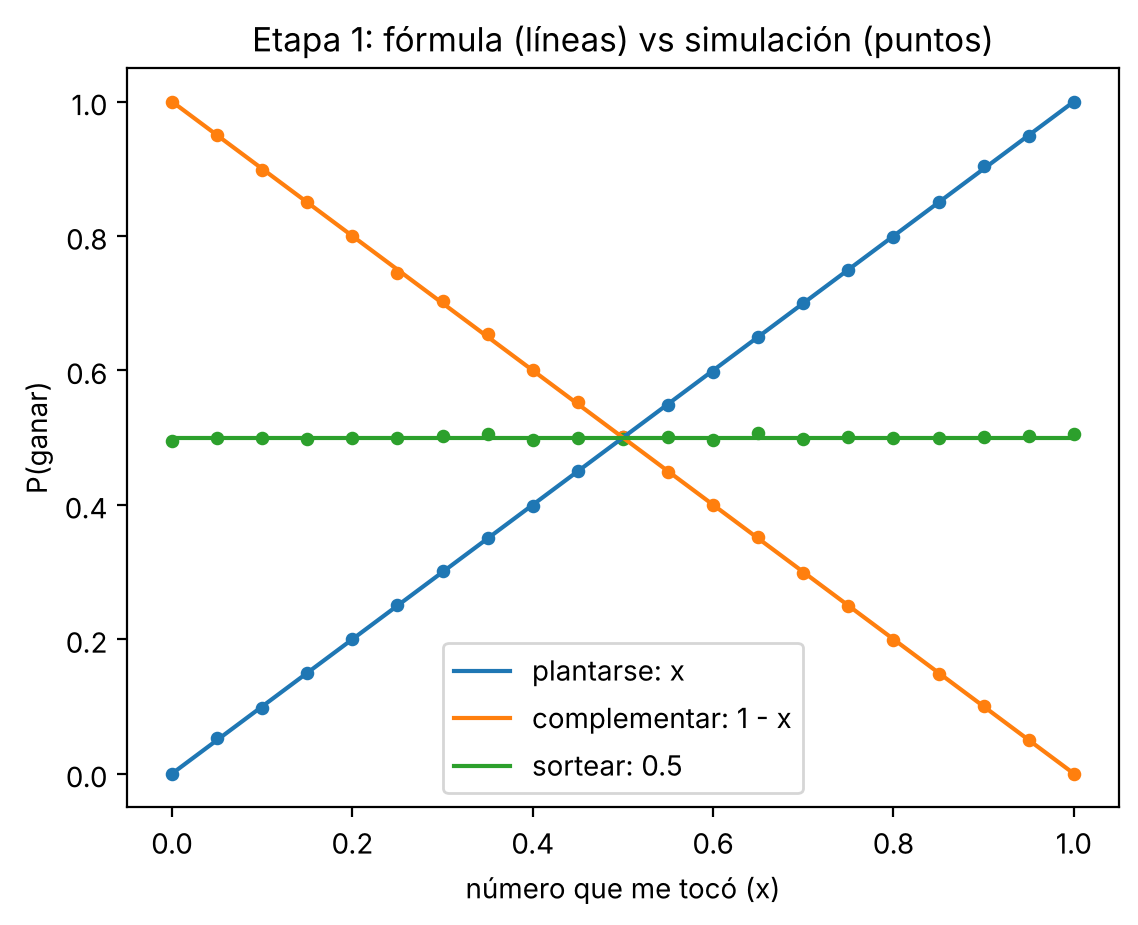

In [4]:
import matplotlib.pyplot as plt

xs = np.linspace(0, 1, 21)    # 0, 0.05, 0.10, ..., 1

sim_plantarse = []
sim_complementar = []
sim_sortear = []

for x in xs:
    p1, p2, p3 = simular_opciones(x, 20000)
    sim_plantarse.append(p1)
    sim_complementar.append(p2)
    sim_sortear.append(p3)

# fórmulas (líneas) vs simulación (puntos)
plt.plot(xs, xs, color="C0", label="plantarse: x")
plt.plot(xs, 1 - xs, color="C1", label="complementar: 1 - x")
plt.plot(xs, [0.5] * len(xs), color="C2", label="sortear: 0.5")

plt.scatter(xs, sim_plantarse, s=15, color="C0")
plt.scatter(xs, sim_complementar, s=15, color="C1")
plt.scatter(xs, sim_sortear, s=15, color="C2")

plt.xlabel("número que me tocó (x)")
plt.ylabel("P(ganar)")
plt.title("Etapa 1: fórmula (líneas) vs simulación (puntos)")
plt.legend()
plt.show()

### Probabilidad total de ganar con esta estrategia

Siempre termino con $\max(x, 1-x)$, que es un número entre 0.5 y 1, y gano con esa misma probabilidad. En promedio:

$$P(\text{ganar}) = E[\max(x, 1-x)] = 0.75$$

Lo comprobamos simulando partidas completas:

In [5]:
def jugar_etapa1(n):
    x = np.random.rand(n)
    mi_numero = np.maximum(x, 1 - x)     # me planto o complemento, el mayor
    rival = np.random.rand(n)
    return np.mean(mi_numero > rival)

print("P(ganar) simulada:", round(jugar_etapa1(1000000), 4))

P(ganar) simulada: 0.7497


### Demostración matemática de la probabilidad total

Anteriormente determinamos que la mejor estrategia, frente a un rival uniforme sin estrategia, consiste en:

- Complementar cuando el número inicial es menor que 0,5.
- Plantarse cuando el número inicial es mayor o igual que 0,5.

Por lo tanto, la probabilidad de ganar depende del número inicial obtenido.

Para calcular la probabilidad total, dividimos el intervalo (0,1) en dos partes e integramos:

$$
P(\text{ganar})=\int_0^{0.5}(1-x)\,dx+\int_{0.5}^{1}x\,dx
$$

Resolviendo ambas integrales:

$$
P(\text{ganar})=0.375+0.375=0.75
$$

- **De 0 a 0,5** conviene complementar: aporta 0,375.
- **De 0,5 a 1** conviene plantarse: aporta 0,375.

**Conclusión:** la estrategia matemática permite ganar el 75% de las partidas, siempre que el rival conserve un número Uniforme(0,1) sin aplicar ninguna estrategia. Este resultado coincide con la simulación anterior, así que ambos métodos (analítico y Monte Carlo) se respaldan entre sí.

In [6]:
from scipy.integrate import quad

def p_complementar(x):
    return 1 - x

def p_plantarse(x):
    return x

# Probabilidad cuando complementamos (x entre 0 y 0.5)
parte1, _ = quad(p_complementar, 0, 0.5)

# Probabilidad cuando nos plantamos (x entre 0.5 y 1)
parte2, _ = quad(p_plantarse, 0.5, 1)

# Sumamos ambas probabilidades
probabilidad_total = parte1 + parte2

print("Primera integral:", parte1)
print("Segunda integral:", parte2)
print("Probabilidad total:", probabilidad_total)
print("Porcentaje:", probabilidad_total * 100, "%")

Primera integral: 0.375
Segunda integral: 0.375
Probabilidad total: 0.75
Porcentaje: 75.0 %


### Comparación de diferentes estrategias

Para comprobar cuál es la estrategia más conveniente, simulamos 100.000 partidas utilizando tres formas de jugar:

- **Plantarse siempre:** conservar el número inicial sin importar su valor.
- **Volver a sortear siempre:** descartar el número inicial y generar uno nuevo.
- **Estrategia matemática:** elegir entre plantarse o complementar, conservando siempre el mayor entre `x` y `1-x`.

Comparamos la probabilidad de ganar de cada estrategia contra un rival que obtiene un número Uniforme(0,1), sin aplicar ninguna estrategia.

Plantarse : 49.8 %
Sortear : 49.84 %
Matemática : 75.04 %


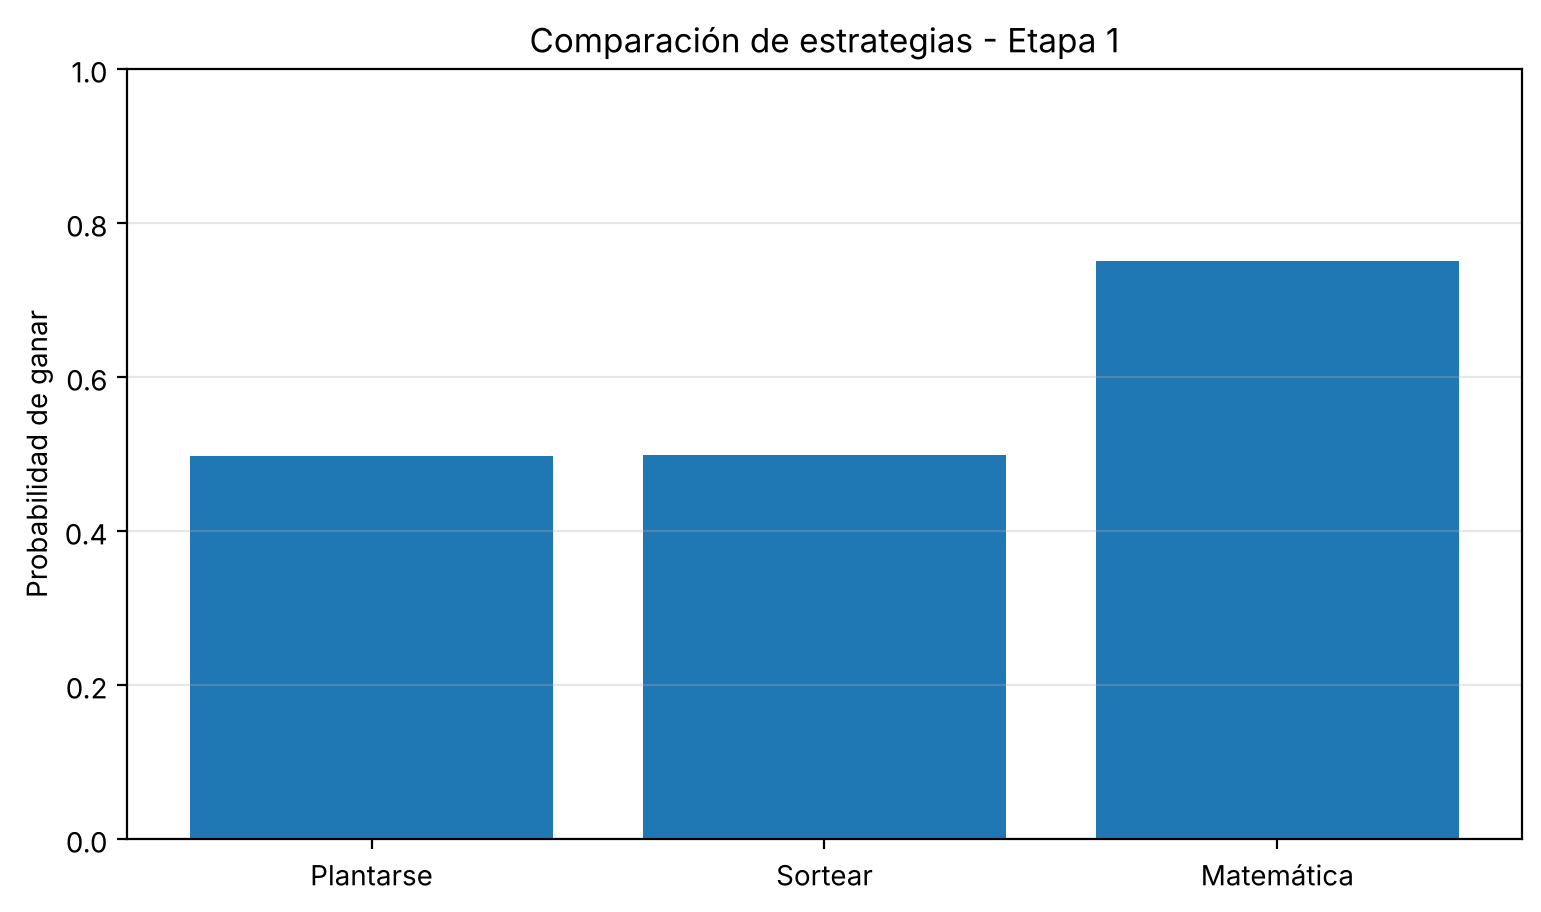

In [7]:
# Cantidad de partidas
n = 100000

# Generamos números aleatorios
x = np.random.rand(n)
rival = np.random.rand(n)
nuevo = np.random.rand(n)

# Estrategia 1: plantarse siempre
ganar_plantarse = np.mean(x > rival)

# Estrategia 2: volver a sortear siempre
ganar_sortear = np.mean(nuevo > rival)

# Estrategia 3: aplicar la estrategia matemática
mi_numero = np.maximum(x, 1 - x)
ganar_matematica = np.mean(mi_numero > rival)

# Guardamos los resultados
estrategias = ["Plantarse", "Sortear", "Matemática"]
resultados = [
    ganar_plantarse,
    ganar_sortear,
    ganar_matematica
]

# Mostramos los resultados
for estrategia, resultado in zip(estrategias, resultados):
    print(estrategia, ":", round(resultado * 100, 2), "%")

# Graficamos
plt.figure(figsize=(9, 5))
plt.bar(estrategias, resultados)

plt.ylabel("Probabilidad de ganar")
plt.title("Comparación de estrategias - Etapa 1")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()


### Análisis de los resultados: comparación de estrategias

Se realizaron 100.000 simulaciones mediante el método de Monte Carlo para comparar tres estrategias posibles frente a un rival con distribución Uniforme(0,1).

Los resultados obtenidos fueron:

- **Plantarse siempre:** 49,80% de victorias.
- **Volver a sortear siempre:** 49,84% de victorias.
- **Estrategia matemática:** 75,04% de victorias.

Observamos que las primeras dos estrategias presentan probabilidades cercanas al 50%, mientras que la estrategia matemática alcanza aproximadamente el 75%.

Esta diferencia se debe a que la estrategia matemática utiliza la información del número inicial para elegir la acción más conveniente: complementar si el número es menor que 0,5 y plantarse si es mayor que 0,5.

Las pequeñas diferencias entre los resultados simulados y los teóricos se explican por la variabilidad aleatoria propia del método de Monte Carlo.

**Conclusión:** bajo el supuesto de que el rival utiliza un número Uniforme(0,1) sin estrategia, tomar decisiones según el valor obtenido aumenta considerablemente la probabilidad de ganar. Sin embargo, todavía debemos analizar si esta estrategia continúa siendo óptima cuando el segundo jugador también toma decisiones estratégicas.

### Convergencia de Monte Carlo

Para analizar cómo influye la cantidad de simulaciones en la precisión de los resultados, ejecutamos el juego con diferentes cantidades de partidas: 100, 1.000, 10.000 y 100.000.

Comparamos las probabilidades simuladas con el resultado teórico de 0,75.

Nuestra hipótesis es que, al aumentar la cantidad de partidas, la probabilidad estimada se estabilizará cada vez más cerca del valor teórico.

100 partidas: 79.0 %
1000 partidas: 76.8 %
10000 partidas: 75.26 %
100000 partidas: 75.1 %


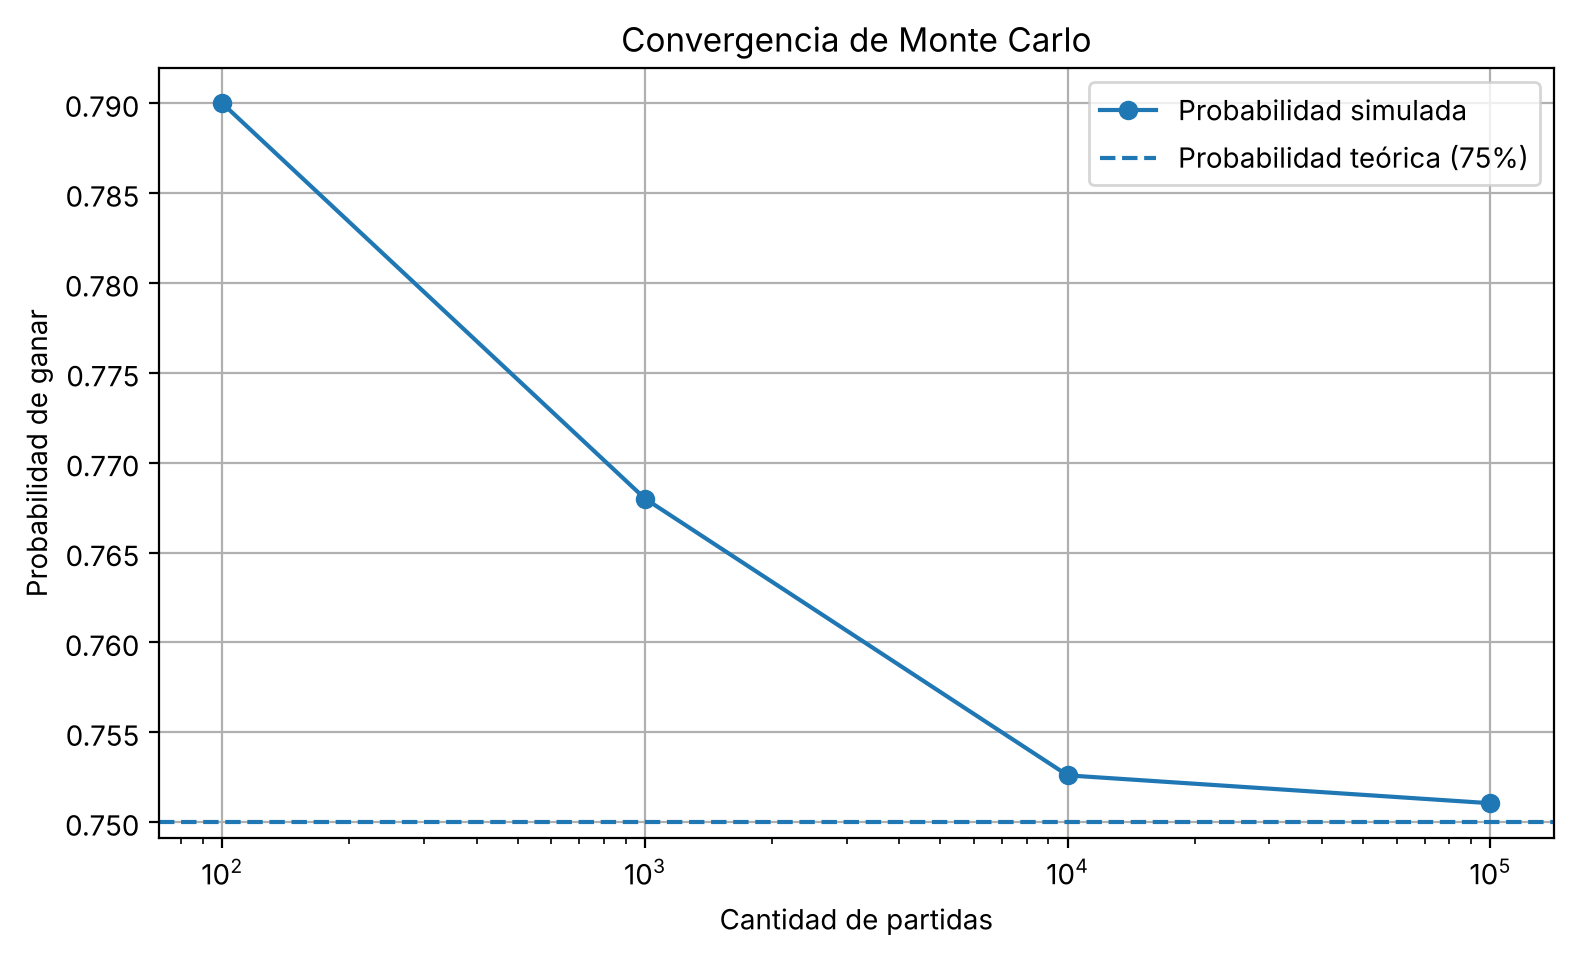

In [8]:

# Diferentes cantidades de partidas
cantidades = [100, 1000, 10000, 100000]

resultados = []

for n in cantidades:

    probabilidad = jugar_etapa1(n)

    resultados.append(probabilidad)

    print(
        n, "partidas:",
        round(probabilidad * 100, 2), "%"
    )

# Gráfico de convergencia
plt.figure(figsize=(9, 5))

plt.plot(
    cantidades,
    resultados,
    marker="o",
    label="Probabilidad simulada"
)

plt.axhline(
    0.75,
    linestyle="--",
    label="Probabilidad teórica (75%)"
)

plt.xscale("log")
plt.xlabel("Cantidad de partidas")
plt.ylabel("Probabilidad de ganar")
plt.title("Convergencia de Monte Carlo")

plt.legend()
plt.grid(True)

plt.show()


### Análisis de la convergencia de Monte Carlo

Para evaluar la precisión del método de Monte Carlo, realizamos simulaciones con diferentes cantidades de partidas: 100, 1.000, 10.000 y 100.000.

Los resultados obtenidos fueron:

| Partidas | Probabilidad de ganar |
|---|---|
| 100 | 79,00% |
| 1.000 | 76,80% |
| 10.000 | 75,26% |
| 100.000 | 75,10% |

Observamos que las probabilidades simuladas se mantienen cercanas al valor teórico del 75%.

Aunque los resultados presentan pequeñas fluctuaciones debido a la aleatoriedad, al aumentar la cantidad de partidas disminuye el error estadístico esperado.

Con 100 partidas el resultado se aleja 4 puntos del teórico (79%), mientras que con 100.000 partidas obtuvimos 75,10%, a solo 0,1 puntos del 75%.

**Conclusión:** los resultados respaldan el cálculo matemático de la Etapa 1 y muestran que Monte Carlo permite estimar probabilidades mediante simulaciones aleatorias.

### Margen de error de la simulación

Las probabilidades calculadas mediante Monte Carlo son estimaciones, ya que dependen de números aleatorios.

Para medir su precisión, calculamos el error estándar de la proporción de victorias y un intervalo de confianza aproximado del 95%.

Utilizamos la fórmula:

$$
EE=\sqrt{\frac{\hat p(1-\hat p)}{n}}
$$

Donde:

- $\hat p$: probabilidad de ganar estimada.
- $n$: cantidad de partidas simuladas.

Para obtener el margen de error aproximado al 95%, multiplicamos el error estándar por 1,96.

Esto permite expresar la probabilidad estimada junto con su incertidumbre, en lugar de presentar únicamente un valor puntual.

In [9]:
# Cantidad de simulaciones
n = 100000

# Probabilidad estimada
p = jugar_etapa1(n)

# Calculamos el error estándar
error_estandar = np.sqrt(p * (1 - p) / n)

# Margen de error para un 95% de confianza
margen_error = 1.96 * error_estandar

# Límites del intervalo
limite_inferior = p - margen_error
limite_superior = p + margen_error

print("Probabilidad estimada:", round(p, 4))
print("Error estándar:", round(error_estandar, 5))
print("Margen de error (95%):", round(margen_error, 5))

print("Resultado:",
      round(p, 4), "±", round(margen_error, 4))

print("Intervalo de confianza:",
      round(limite_inferior, 4),
      "a",
      round(limite_superior, 4))


Probabilidad estimada: 0.7512
Error estándar: 0.00137
Margen de error (95%): 0.00268
Resultado: 0.7512 ± 0.0027
Intervalo de confianza: 0.7485 a 0.7539


### ¿Qué falla de esta etapa?

El resultado dice que ganamos el 75% de las veces, pero **el rival también puede elegir**. Si el Jugador 2 usa la misma estrategia, cada uno gana el 50%. Entonces el supuesto "rival uniforme (0,1)" no es realista: el rival también se queda con su mayor número, que está entre 0.5 y 1.

En la etapa 2 incorporamos la decisión del Jugador 2, que además conoce la opción que eligió el Jugador 1.

## Etapa 2: el juego completo

### Hipótesis

1. Los dos jugadores eligen para **maximizar su probabilidad de ganar**.
2. El Jugador 2 conoce la **opción** que eligió el Jugador 1, pero **no su número**.
3. El Jugador 1 usa un **umbral $t$** para clasificar su número:
   - **Alto** ($x \geq t$): se planta.
   - **Bajo** ($x \leq 1-t$): complementa (porque $1-x$ queda alto).
   - **Intermedio** (entre $1-t$ y $t$): sortea de nuevo.
4. El Jugador 2 **sabe qué umbral usa el Jugador 1** (los dos conocen la estrategia óptima del otro).
5. Los números son independientes y la probabilidad de empate es 0.

### Método

Resolvemos de forma **secuencial**: primero vemos qué le conviene al Jugador 2 según lo que anunció el Jugador 1, y después buscamos el mejor $t$ para el Jugador 1.

### 2.1. El Jugador 2 cuando el Jugador 1 sorteó

Si J1 sorteó, su número final es un número nuevo al azar: **uniforme (0,1)**. Es exactamente la situación de la etapa 1, pero del lado del Jugador 2.

Entonces J2 compara $y$, $1-y$ y $0.5$, y como siempre uno de los dos primeros es al menos 0.5, **J2 nunca sortea**: se queda con $\max(y, 1-y)$.

In [10]:
# Si J1 sorteó, su número es uniforme (0,1): J2 usa la misma función de la etapa 1
for y in [0.9, 0.2, 0.45]:
    opcion, prob = mejor_opcion(y)
    print("J2 con y =", y, "→", opcion, "con P(ganar) =", round(prob, 2))

J2 con y = 0.9 → plantarse con P(ganar) = 0.9
J2 con y = 0.2 → complementar con P(ganar) = 0.8
J2 con y = 0.45 → complementar con P(ganar) = 0.55


### 2.2. El Jugador 2 cuando el Jugador 1 se plantó o complementó

- Si J1 **se plantó**, J2 sabe que $x \geq t$.
- Si J1 **complementó**, J2 sabe que $x \leq 1-t$, entonces su número final $1-x \geq t$.

En los dos casos el número de J1 es **uniforme entre $t$ y 1**. Para J2, los dos anuncios dan **la misma información**: "J1 tiene un número alto".

J2 se queda con $m = \max(y, 1-y)$ o sortea:

- **Quedarse con $m$:** gana si J1 tiene menos que $m$ → $P = \dfrac{m - t}{1 - t}$ (si $m < t$, pierde seguro).
- **Sortear:** un número nuevo le gana al de J1 en promedio con $P = 1 - E[\text{J1}] = 1 - \dfrac{1+t}{2} = \dfrac{1-t}{2}$.

Conviene quedarse si:

$$\frac{m - t}{1 - t} \geq \frac{1 - t}{2} \iff m \geq \frac{1 + t^2}{2} = s$$

**Ejemplo con $t = 0.63$:** sortear da $0.185$. Con $m = 0.70$, quedarse da $0.189$ (apenas mejor). El umbral es $s \approx 0.698$.

**Estrategia de J2:** si $m \geq s$ se queda con $m$ (se planta o complementa); si no, sortea.

In [11]:
def p_quedarse_j2(m, t):
    # J1 se quedó: tiene un número uniforme entre t y 1
    if m < t:
        return 0
    return (m - t) / (1 - t)

def p_sortear_j2(t):
    promedio_j1 = (1 + t) / 2
    return 1 - promedio_j1

def umbral_j2(t):
    return (1 + t**2) / 2

t = 0.63
print("Umbral de J2:", round(umbral_j2(t), 3))
print("Sortear da:", round(p_sortear_j2(t), 3))
print()
for m in [0.65, 0.70, 0.80, 0.95]:
    print("m =", m, "| quedarse:", round(p_quedarse_j2(m, t), 3), "| sortear:", round(p_sortear_j2(t), 3))

Umbral de J2: 0.698
Sortear da: 0.185

m = 0.65 | quedarse: 0.054 | sortear: 0.185
m = 0.7 | quedarse: 0.189 | sortear: 0.185
m = 0.8 | quedarse: 0.459 | sortear: 0.185
m = 0.95 | quedarse: 0.865 | sortear: 0.185


In [12]:
# Verificación por simulación
def simular_j2(m, t, n):
    j1 = np.random.uniform(t, 1, n)     # número de J1, uniforme entre t y 1
    nuevo = np.random.rand(n)           # número nuevo si J2 sortea
    gana_quedarse = np.mean(m > j1)
    gana_sortear = np.mean(nuevo > j1)
    return gana_quedarse, gana_sortear

for m in [0.65, 0.70, 0.80, 0.95]:
    p1, p2 = simular_j2(m, 0.63, 100000)
    print("m =", m, "| quedarse:", round(p1, 3), "| sortear:", round(p2, 3))

m = 0.65 | quedarse: 0.055 | sortear: 0.184
m = 0.7 | quedarse: 0.19 | sortear: 0.187
m = 0.8 | quedarse: 0.461 | sortear: 0.184
m = 0.95 | quedarse: 0.865 | sortear: 0.188


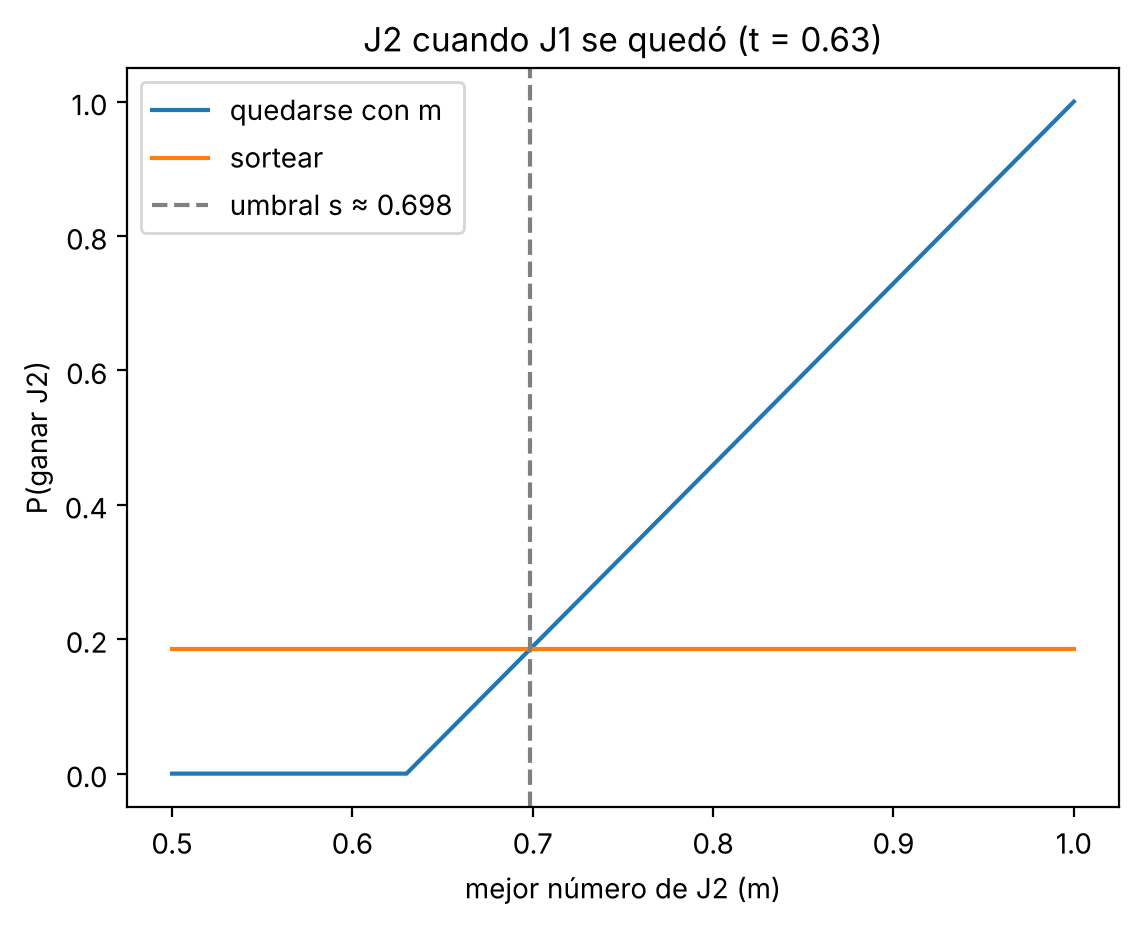

In [13]:
ms = np.linspace(0.5, 1, 51)

quedarse = []
for m in ms:
    quedarse.append(p_quedarse_j2(m, t))

plt.plot(ms, quedarse, label="quedarse con m")
plt.plot(ms, [p_sortear_j2(t)] * len(ms), label="sortear")
plt.axvline(umbral_j2(t), color="gray", linestyle="--", label="umbral s ≈ 0.698")
plt.xlabel("mejor número de J2 (m)")
plt.ylabel("P(ganar J2)")
plt.title("J2 cuando J1 se quedó (t = 0.63)")
plt.legend()
plt.show()

### 2.3. El mejor umbral para el Jugador 1

J1 ya sabe cómo responde J2 y compara:

**Si sortea:** J2 nunca sortea (2.1), entonces el número de J2 es $\max(y, 1-y)$, uniforme entre 0.5 y 1, con promedio 0.75. J1 gana con

$$P = 1 - 0.75 = 0.25$$

**Si se queda con $z$** (entre $t$ y $s$): J2 sortea con probabilidad $P(m < s) = 2s - 1 = t^2$, y en ese caso J1 gana si el número nuevo es menor que $z$. Si J2 no sortea, tiene $\geq s$ y J1 pierde:

$$P = t^2 \cdot z$$

**El umbral** es donde le da igual quedarse con $z = t$ o sortear:

$$t^2 \cdot t = 0.25 \iff t^3 = \frac14 \iff t^* = \sqrt[3]{0.25} \approx 0.630$$

Y entonces el umbral de J2 es $s^* = \dfrac{1 + t^{*2}}{2} \approx 0.698$.

**Ejemplos:** quedarse con 0.63 da $0.63^3 \approx 0.25$ (igual que sortear). Quedarse con 0.55 da $0.397 \cdot 0.55 \approx 0.218 < 0.25$ → conviene sortear.

In [14]:
def p_j1_se_queda(z, t):
    s = umbral_j2(t)
    p = (2 * s - 1) * z               # J2 sorteó y su número nuevo es menor que z
    if z > s:
        p = p + 2 * (z - s)           # J2 se quedó con algo entre s y z
    return p

t_opt = 0.25 ** (1/3)
s_opt = umbral_j2(t_opt)
print("t* =", round(t_opt, 4), "| s* =", round(s_opt, 4))
print()
for z in [0.55, 0.63, 0.75, 0.9]:
    print("z =", z, "| quedarse:", round(p_j1_se_queda(z, t_opt), 3), "| sortear: 0.25")

t* = 0.63 | s* = 0.6984

z = 0.55 | quedarse: 0.218 | sortear: 0.25
z = 0.63 | quedarse: 0.25 | sortear: 0.25
z = 0.75 | quedarse: 0.401 | sortear: 0.25
z = 0.9 | quedarse: 0.76 | sortear: 0.25


In [15]:
# Verificación: si J1 sortea, gana el 25%
def simular_j1_sortea(n):
    j1 = np.random.rand(n)                 # número nuevo de J1
    y = np.random.rand(n)
    j2 = np.maximum(y, 1 - y)              # J2 nunca sortea
    return np.mean(j1 > j2)

print("P(gana J1 si sortea) simulada:", round(simular_j1_sortea(1000000), 4))

P(gana J1 si sortea) simulada: 0.2504


### 2.4. El juego completo

Simulamos partidas completas con los dos jugadores decidiendo:

1. J1 saca $x$. Si $\max(x, 1-x) \geq t$ se queda con ese número; si no, sortea.
2. J2 saca $y$. Si J1 sorteó, se queda con $\max(y, 1-y)$. Si J1 se quedó, usa el umbral $s$.
3. Gana el número más alto.

Primero hacemos un **barrido**: probamos muchos valores de $t$ y, para cada uno, J2 responde con su mejor umbral $s(t)$. Buscamos el $t$ donde J1 gana más.

In [16]:
def jugar(t, n):
    s = umbral_j2(t)

    # Jugador 1
    x = np.random.rand(n)
    m1 = np.maximum(x, 1 - x)
    j1_sortea = m1 < t
    z = np.where(j1_sortea, np.random.rand(n), m1)

    # Jugador 2 (su umbral depende de lo que hizo J1)
    y = np.random.rand(n)
    m2 = np.maximum(y, 1 - y)
    umbral = np.where(j1_sortea, 0.5, s)
    w = np.where(m2 < umbral, np.random.rand(n), m2)

    return np.mean(z > w)        # proporción de partidas que gana J1

Mejor umbral encontrado por simulación: 0.66


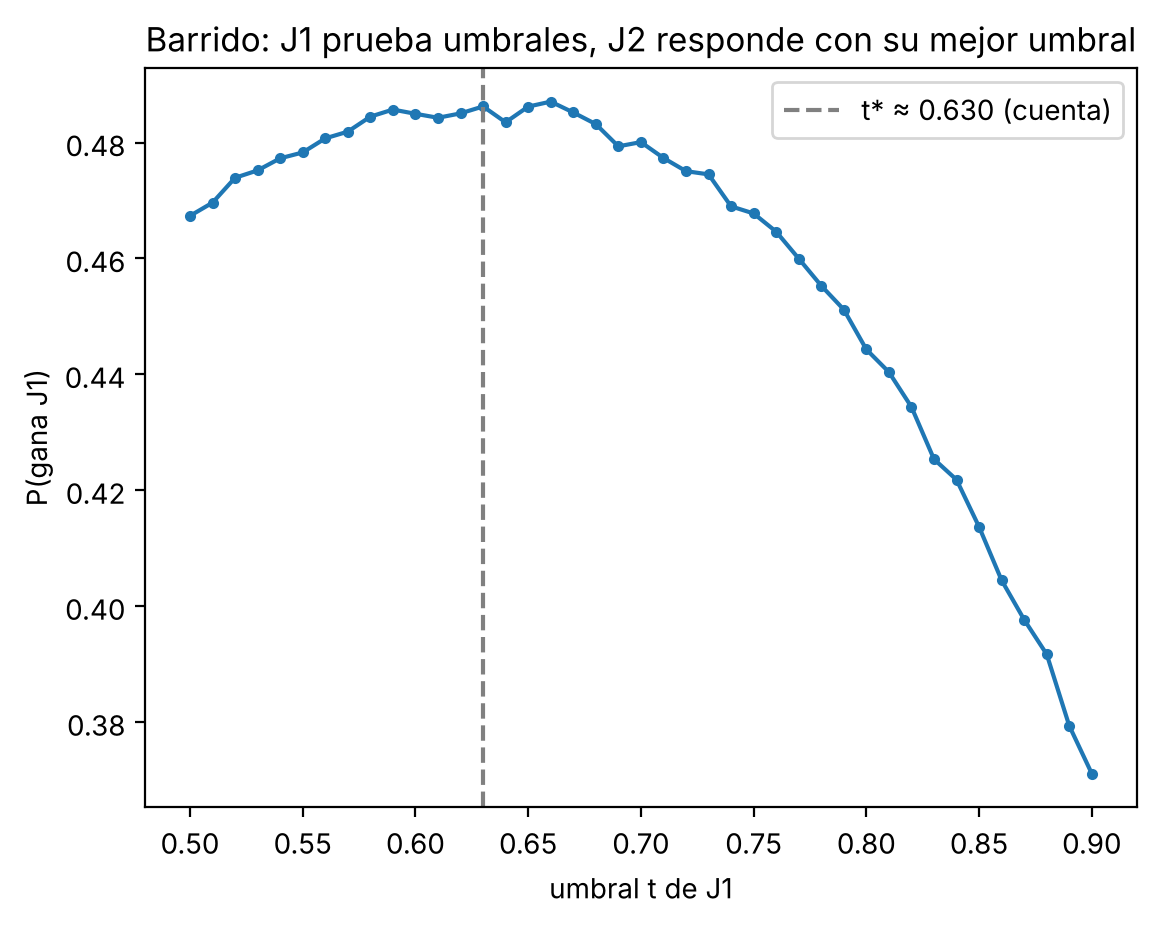

In [17]:
ts = np.linspace(0.5, 0.9, 41)

resultados = []
for t in ts:
    resultados.append(jugar(t, 200000))

mejor = ts[np.argmax(resultados)]
print("Mejor umbral encontrado por simulación:", round(mejor, 3))

plt.plot(ts, resultados, marker="o", markersize=3)
plt.axvline(t_opt, color="gray", linestyle="--", label="t* ≈ 0.630 (cuenta)")
plt.xlabel("umbral t de J1")
plt.ylabel("P(gana J1)")
plt.title("Barrido: J1 prueba umbrales, J2 responde con su mejor umbral")
plt.legend()
plt.show()

In [18]:
p_j1 = jugar(t_opt, 5000000)
print("P(gana J1) =", round(p_j1, 4))
print("P(gana J2) =", round(1 - p_j1, 4))
print("Fórmula: P(gana J1) = 1/4 + 3t*/8 =", round(0.25 + 3 * t_opt / 8, 4))

P(gana J1) = 0.4863
P(gana J2) = 0.5137
Fórmula: P(gana J1) = 1/4 + 3t*/8 = 0.4862


### Conclusión

**Estrategia óptima del Jugador 1:**

- Si $\max(x, 1-x) \geq 0.630$: se queda con ese número (se planta si $x \geq 0.5$, complementa si $x < 0.5$).
- Si no (o sea, $x$ entre 0.370 y 0.630): sortea de nuevo.

**Estrategia óptima del Jugador 2:**

- Si J1 sorteó: nunca sortea, se queda con $\max(y, 1-y)$.
- Si J1 se plantó o complementó: se queda con $\max(y, 1-y)$ solo si es $\geq 0.698$; si no, sortea.

**Resultado:** jugando ambos de forma óptima,

$$P(\text{gana J1}) = \frac14 + \frac{3t^*}{8} \approx 0.486 \qquad P(\text{gana J2}) \approx 0.514$$

**El Jugador 2 tiene ventaja**, porque decide conociendo la opción que eligió el Jugador 1.